# WICOS: pre-processing step by step
Each spectrogram is pre-processed in four steps (`preprocess_clip` in `src/preprocessing.py`):
1. **Noise removal:** one noise level per clip, the median of the **far Doppler bins** (|bin − 400| ≥ 340) that the hand never reaches.
   Every pixel not more than a **margin** of 10 dB above that level is set to the threshold (noise level + margin).
2. **Doppler crop:** keep the bins between the two far-bin regions (bins 60–739).
3. **Scaling:** map each clip so its threshold becomes 0 and its maximum 1.
4. **Resize:** interpolate each clip to 128 × 128 (Doppler × time).

This notebook **shows** what every step does, with plots. Where the numbers (far bins, margin, crop) come from is derived in
`2a_preprocessing_parameters.ipynb`, on the training samples only. Every step uses only the sample itself and these fixed constants,
so it can be applied to all samples without leaking test information.

## Set-up

In [2]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

sys.path.insert(0, str(Path("../src").resolve()))
import preprocessing
from preprocessing import (DOPPLER_CROP, FAR_BINS, FAR_OFFSET, MARGIN_DB, ZERO_DOPPLER,  # ZERO_DOPPLER = 400
                           noise_level, preprocess, preprocess_clip, remove_noise)
from build_dataset import GESTURES, SEED, load_data, split

FIG_DIR = Path("../reports/figures")
FAR_RANGES = [(0, ZERO_DOPPLER - FAR_OFFSET), (ZERO_DOPPLER + FAR_OFFSET, 2 * ZERO_DOPPLER)]  # (0, 60), (740, 800)

In [3]:
# Load all spectrograms (dB, Doppler bins x time bins) and the train/test split, as in build_dataset.py
spectrograms, metadata = load_data()
idx_train, idx_test, _ = split(metadata)
train_specs = [spectrograms[i] for i in idx_train]
labels_train = metadata.label.to_numpy()[idx_train]

# Example plots: the first training sample of each gesture (indices into train_specs)
GESTURE_EXAMPLES = [np.flatnonzero(labels_train == j)[0] for j in range(len(GESTURES))]
print(f"{len(spectrograms)} samples, {len(idx_train)} for training")

960 samples, 768 for training


## Noise removal
The gesture sits in a band around zero Doppler (bin 400); the Doppler bins far from it contain only noise. Each sample's
**noise level** is the median of these **far bins**: bins 0–59 and 740–799 (|bin − 400| ≥ 340).

The noise spreads around this level, so half of the noise pixels lie above it. To tell gesture from noise we need a **margin**
above the level that pure noise almost never exceeds. The margin is 10 dB: the 99.9th percentile of the far-bin noise of all
training samples (derived in `2a_preprocessing_parameters.ipynb`).

### Which Doppler bins contain only noise?
We look at the level of each Doppler bin over all training samples:
- Each sample's level is first taken relative to its own noise level (far-bin median), so recordings with a different gain line up.
- **Median over time:** the typical level of a Doppler bin. Pure noise gives a flat line; a gesture gives a bump around zero Doppler (bin 400).
- **99th percentile over time:** a gesture can be short, so it may not move the median. The 99th percentile shows whether a bin *ever* gets loud.

The lines are the median over the samples, the bands the 5–95% spread between samples. Both lines are flat at the edges and only
rise well inside them, so the far bins (grey) contain only noise.

In [4]:
# Level of every Doppler bin over all training samples, relative to each sample's noise level
EDGE_BINS = 50  # outermost bins on each side that set the reference "edge" level
RISE_DB = 1     # a bin "rises" when its level is this many dB above the edge level

levels = {
    "median over time": np.stack([np.median(x, axis=1) - noise_level(x) for x in train_specs]),            # samples x bins
    "99th percentile over time": np.stack([np.percentile(x, 99, axis=1) - noise_level(x) for x in train_specs]),
}
for name, level in levels.items():
    profile = np.median(level, axis=0)
    edge = np.median(np.r_[profile[:EDGE_BINS], profile[-EDGE_BINS:]])
    above = np.flatnonzero(profile > edge + RISE_DB)
    print(f"{name:>26}: edge level {edge:5.1f} dB, rises > {RISE_DB} dB between bins {above.min()} and {above.max()}")

          median over time: edge level  -0.0 dB, rises > 1 dB between bins 282 and 525
 99th percentile over time: edge level   7.4 dB, rises > 1 dB between bins 224 and 569


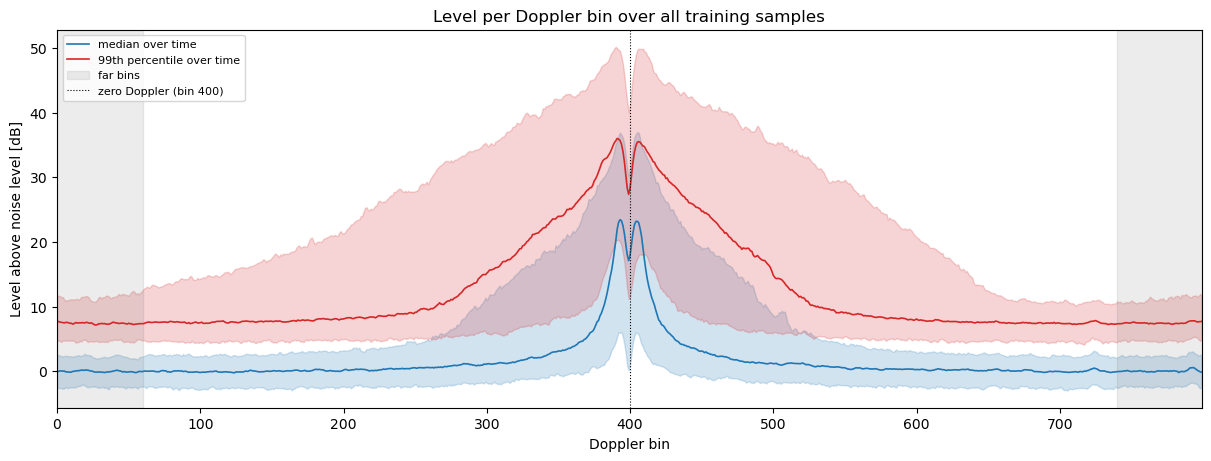

In [5]:
# Level per Doppler bin: median over the samples (line) and 5-95% spread between samples (band)
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
for (name, level), color in zip(levels.items(), ["C0", "C3"]):
    bins = np.arange(level.shape[1])
    ax.plot(bins, np.median(level, axis=0), color=color, linewidth=1.2, label=name)
    ax.fill_between(bins, *np.percentile(level, [5, 95], axis=0), color=color, alpha=0.2)

for k, (lo, hi) in enumerate(FAR_RANGES):
    ax.axvspan(lo, hi, color="gray", alpha=0.15, label="far bins" if k == 0 else None)
ax.axvline(ZERO_DOPPLER, color="black", linestyle=":", linewidth=0.8, label=f"zero Doppler (bin {ZERO_DOPPLER})")
ax.set_xlim(0, bins[-1])
ax.set_title("Level per Doppler bin over all training samples")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Level above noise level [dB]")
ax.legend(fontsize=8, loc="upper left")
fig.savefig(FIG_DIR / "prepro_doppler_profile.pdf", bbox_inches="tight")
plt.show()

In [6]:
# How far pure noise rises above the noise level: pooled far-bin pixels of all training samples.
# These include the short broadband click stripes; 2a_preprocessing_parameters.ipynb leaves the stripe frames out
# (pure noise: P99 8.3 dB, P99.9 10.2 dB, which sets the 10 dB margin).
far_noise = np.concatenate([(x[FAR_BINS] - noise_level(x)).ravel() for x in train_specs])
p99, p999 = np.percentile(far_noise, [99, 99.9])
print(f"Far-bin pixels (stripes included) above the noise level: P99 {p99:.1f} dB, P99.9 {p999:.1f} dB; margin {MARGIN_DB:.0f} dB "
      f"keeps {(far_noise > MARGIN_DB).mean():.2%} of the noise pixels")

Far-bin pixels (stripes included) above the noise level: P99 8.7 dB, P99.9 13.4 dB; margin 10 dB keeps 0.39% of the noise pixels


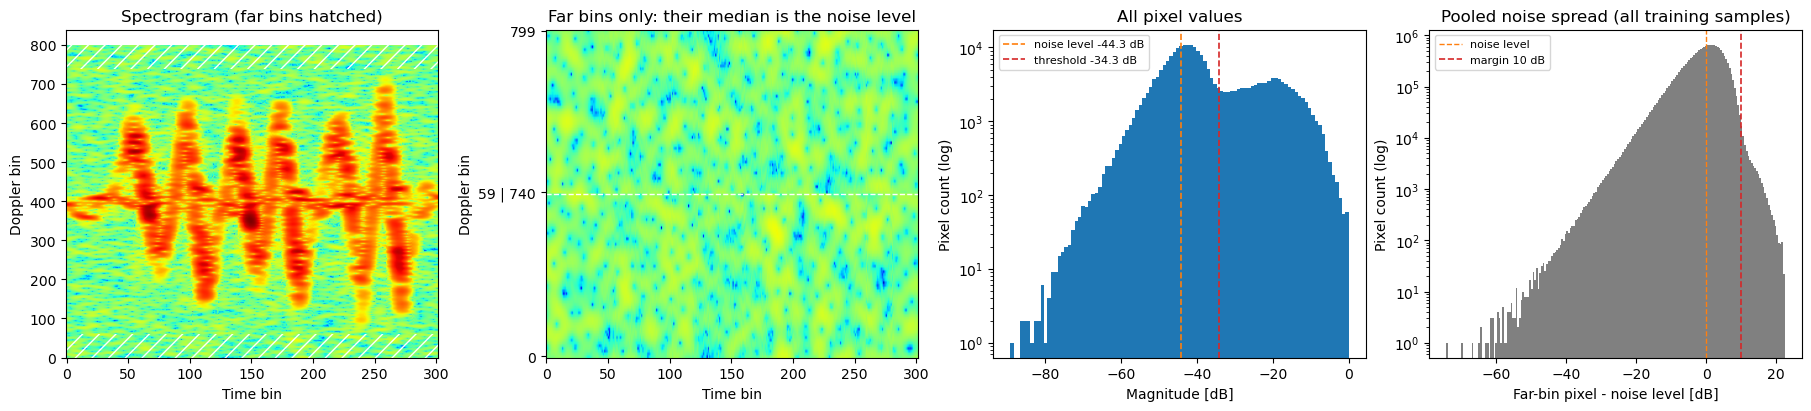

In [7]:
# Steps of the noise removal for one training sample, and the pooled noise of all training samples
x_ex = train_specs[2]
level_ex = noise_level(x_ex)
far_ex = x_ex[FAR_BINS]  # far bins stacked: 120 x time bins

fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)

# 1. Full spectrogram, far bins marked
axes[0].imshow(x_ex, aspect="auto", origin="lower", cmap="jet")
for lo, hi in FAR_RANGES:
    axes[0].axhspan(lo, hi, facecolor="none", edgecolor="white", hatch="//", linewidth=0)
axes[0].set_title("Spectrogram (far bins hatched)")
axes[0].set_xlabel("Time bin")
axes[0].set_ylabel("Doppler bin")

# 2. Only the far bins, stacked; dashed line where the two ranges meet
n_low = FAR_RANGES[0][1] - FAR_RANGES[0][0]
axes[1].imshow(far_ex, aspect="auto", origin="lower", cmap="jet", vmin=x_ex.min(), vmax=x_ex.max())
axes[1].axhline(n_low - 0.5, color="white", linestyle="--", linewidth=1)
axes[1].set_yticks([0, n_low, len(FAR_BINS) - 1],
                   [FAR_BINS[0], f"{FAR_BINS[n_low - 1]} | {FAR_BINS[n_low]}", FAR_BINS[-1]])
axes[1].set_title("Far bins only: their median is the noise level")
axes[1].set_xlabel("Time bin")
axes[1].set_ylabel("Doppler bin")

# 3. All pixel values of the sample, with the noise level and the threshold
axes[2].hist(x_ex.ravel(), bins=100, color="C0")
axes[2].axvline(level_ex, color="C1", linestyle="--", linewidth=1.2, label=f"noise level {level_ex:.1f} dB")
axes[2].axvline(level_ex + MARGIN_DB, color="C3", linestyle="--", linewidth=1.2,
                label=f"threshold {level_ex + MARGIN_DB:.1f} dB")
axes[2].set_yscale("log")
axes[2].set_title("All pixel values")
axes[2].set_xlabel("Magnitude [dB]")
axes[2].set_ylabel("Pixel count (log)")
axes[2].legend(fontsize=8)

# 4. Noise spread: far-bin pixels minus their noise level, pooled over all training samples
axes[3].hist(far_noise, bins=200, color="gray")
axes[3].axvline(0, color="C1", linestyle="--", linewidth=1, label="noise level")
axes[3].axvline(MARGIN_DB, color="C3", linestyle="--", linewidth=1.2, label=f"margin {MARGIN_DB:.0f} dB")
axes[3].set_yscale("log")  # log scale so the tail is visible
axes[3].set_title("Pooled noise spread (all training samples)")
axes[3].set_xlabel("Far-bin pixel - noise level [dB]")
axes[3].set_ylabel("Pixel count (log)")
axes[3].legend(fontsize=8)

fig.savefig(FIG_DIR / "prepro_noise_steps.pdf", bbox_inches="tight")
plt.show()

**Noise removal strategy.** Per sample, the threshold is the noise level (median of the far bins) plus the margin:

$$\text{threshold} = \operatorname{median}(x_\text{far bins}) + 10\ \text{dB}$$

Pixels at or below the threshold count as noise and are set to the threshold. Pixels above it count as gesture. Only about 0.1%
of the pure-noise pixels lie above the threshold (0.4% if the short broadband click stripes are counted as well), so very little
noise is mistaken for gesture. The noise level is taken per
sample, so the threshold follows each recording's own noise; the margin is the same for all samples.

### Removing the noise
We apply the threshold to every spectrogram. The noise-free spectrograms stay in dB; scaling to [0, 1] happens at the end, after the Doppler crop.

The plot after the next cell shows the steps for a few training samples (one row each):
1. **Spectrogram:** the raw sample in dB.
2. **Pixel values:** all pixels sorted from small to large. The dotted line is the noise level, the dashed line the threshold (noise level + margin), and the grey area below it is the noise that will be removed.
3. **Noise removed:** every pixel below the threshold is set to the threshold, so only the gesture stands out (same dB colour scale as the raw spectrogram).

In [8]:
# remove_noise (src/preprocessing.py): set every pixel at or below the threshold (noise level + margin) to the threshold
spectrograms_clean, thresholds = zip(*(remove_noise(x) for x in spectrograms))
spectrograms_clean, thresholds = list(spectrograms_clean), np.array(thresholds)

removed = np.array([(x <= t).mean() for x, t in zip(spectrograms, thresholds)])
print(f"{len(spectrograms_clean)} spectrograms cleaned; threshold {thresholds.min():.1f} to {thresholds.max():.1f} dB, "
      f"pixels removed per sample {removed.min():.1%} to {removed.max():.1%} (mean {removed.mean():.1%})")

960 spectrograms cleaned; threshold -49.4 to -6.9 dB, pixels removed per sample 59.0% to 99.4% (mean 89.7%)


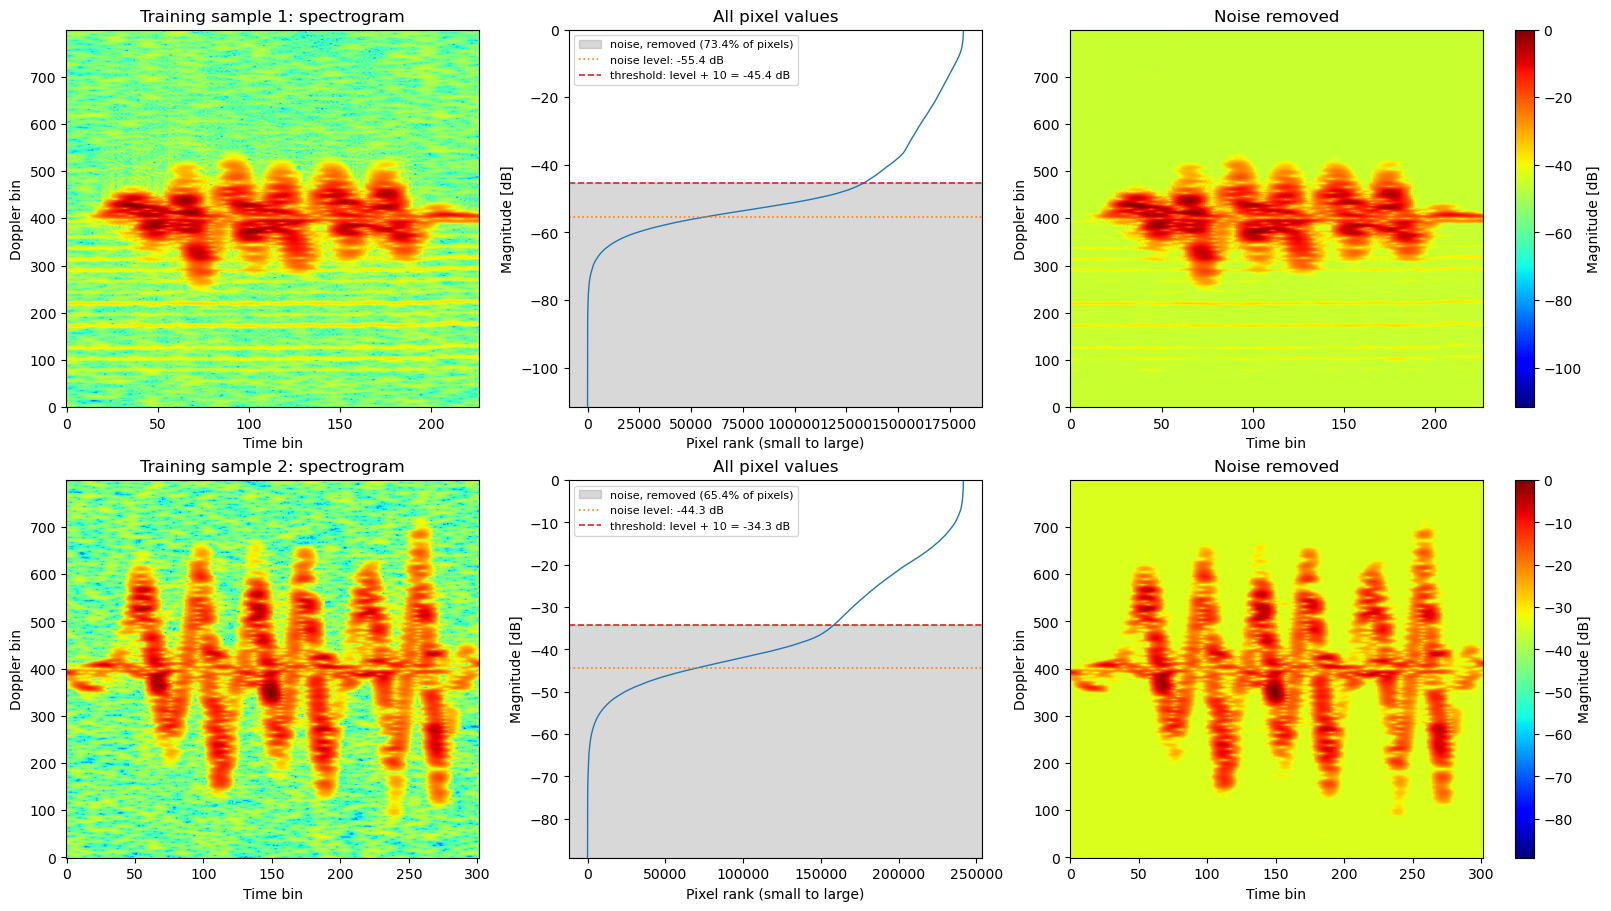

In [9]:
# Noise removal for a few example training samples, one row per sample
EXAMPLES = [1, 2]  # indices into train_specs

fig, axes = plt.subplots(len(EXAMPLES), 3, figsize=(16, 4.5 * len(EXAMPLES)), constrained_layout=True)

for row, i in zip(axes, EXAMPLES):
    x = train_specs[i]
    x_clean, threshold = spectrograms_clean[idx_train[i]], thresholds[idx_train[i]]
    level = noise_level(x)
    pixels = np.sort(x.ravel())
    noise_share = (pixels <= threshold).mean()
    vmin, vmax = x.min(), x.max()  # same colour scale for the raw and noise-removed spectrograms

    # 1. Raw spectrogram
    row[0].imshow(x, aspect="auto", origin="lower", cmap="jet", vmin=vmin, vmax=vmax)
    row[0].set_title(f"Training sample {i}: spectrogram")
    row[0].set_xlabel("Time bin")
    row[0].set_ylabel("Doppler bin")

    # 2. All pixel values, sorted, with the noise level, the threshold and the noise area below it
    row[1].plot(pixels, color="C0", linewidth=1)
    row[1].axhspan(vmin, threshold, color="gray", alpha=0.3, label=f"noise, removed ({noise_share:.1%} of pixels)")
    row[1].axhline(level, color="C1", linestyle=":", linewidth=1.2, label=f"noise level: {level:.1f} dB")
    row[1].axhline(threshold, color="C3", linestyle="--", linewidth=1.2,
                   label=f"threshold: level + {MARGIN_DB:.0f} = {threshold:.1f} dB")
    row[1].set_ylim(vmin, vmax)
    row[1].set_title("All pixel values")
    row[1].set_xlabel("Pixel rank (small to large)")
    row[1].set_ylabel("Magnitude [dB]")
    row[1].legend(fontsize=8, loc="upper left")

    # 3. Spectrogram with the threshold applied (same dB scale as the raw spectrogram)
    im_db = row[2].imshow(x_clean, aspect="auto", origin="lower", cmap="jet", vmin=vmin, vmax=vmax)
    row[2].set_title("Noise removed")
    row[2].set_xlabel("Time bin")
    row[2].set_ylabel("Doppler bin")
    fig.colorbar(im_db, ax=row[2], label="Magnitude [dB]")

fig.savefig(FIG_DIR / "prepro_noise_removal.pdf", bbox_inches="tight")
plt.show()

## Doppler crop

After noise removal, every pixel above the threshold is gesture and every other pixel sits at the threshold. The crop keeps bins
60–739: the complement of the far bins, which contain only noise by construction (`2a_preprocessing_parameters.ipynb`). The plots below
show how much of the gesture that window keeps.

- **Gesture energy per Doppler bin:** the linear power above the threshold, $10^{x/10} - 10^{\text{threshold}/10}$, summed over time. Pixels at the threshold give 0, so only the gesture counts. We normalise it so it sums to 1 per sample.
- **Retained gesture energy:** for a symmetric window $[400 - w, 400 + w)$ around zero Doppler, the share of the gesture energy inside the window.
- **Half-width $w$ per sample:** the smallest $w$ that keeps at least `ENERGY_KEPT` of the gesture energy. The crop has $w$ = 340.

In [10]:
ENERGY_KEPT = 0.99                         # share of the gesture energy a window must keep
HALF_WIDTHS = np.arange(ZERO_DOPPLER + 1)  # candidate half-widths w of the window [ZERO_DOPPLER - w, ZERO_DOPPLER + w)
W_CROP = ZERO_DOPPLER - DOPPLER_CROP[0]    # half-width of the crop: 340

def retained_energy(x_clean, threshold):
    """Share of the gesture energy inside [ZERO_DOPPLER - w, ZERO_DOPPLER + w) for every half-width w."""
    power = 10 ** (x_clean / 10) - 10 ** (threshold / 10)  # power above the threshold: 0 for removed noise
    energy = power.sum(axis=1)                               # gesture energy per Doppler bin
    cum = np.r_[0, np.cumsum(energy / energy.sum())]         # normalised, cumulative over Doppler bins
    return cum[ZERO_DOPPLER + HALF_WIDTHS] - cum[ZERO_DOPPLER - HALF_WIDTHS]

def smallest_half_width(retained, kept=ENERGY_KEPT):
    """Smallest w whose window keeps at least `kept` of the gesture energy."""
    return int(np.argmax(retained >= kept))

In [11]:
# Retained gesture energy against w, and the smallest half-width w, for every training sample
retained_train = np.stack([retained_energy(spectrograms_clean[i], thresholds[i]) for i in idx_train])  # samples x w
w_kept_train = np.array([smallest_half_width(r) for r in retained_train])
print(f"Half-width w over {len(w_kept_train)} training samples: median {np.median(w_kept_train):.0f}, "
      f"max {w_kept_train.max()}; energy kept by the crop (w = {W_CROP}): "
      f"median {np.median(retained_train[:, W_CROP]):.2%}, min {retained_train[:, W_CROP].min():.2%}")

Half-width w over 768 training samples: median 88, max 357; energy kept by the crop (w = 340): median 100.00%, min 98.48%


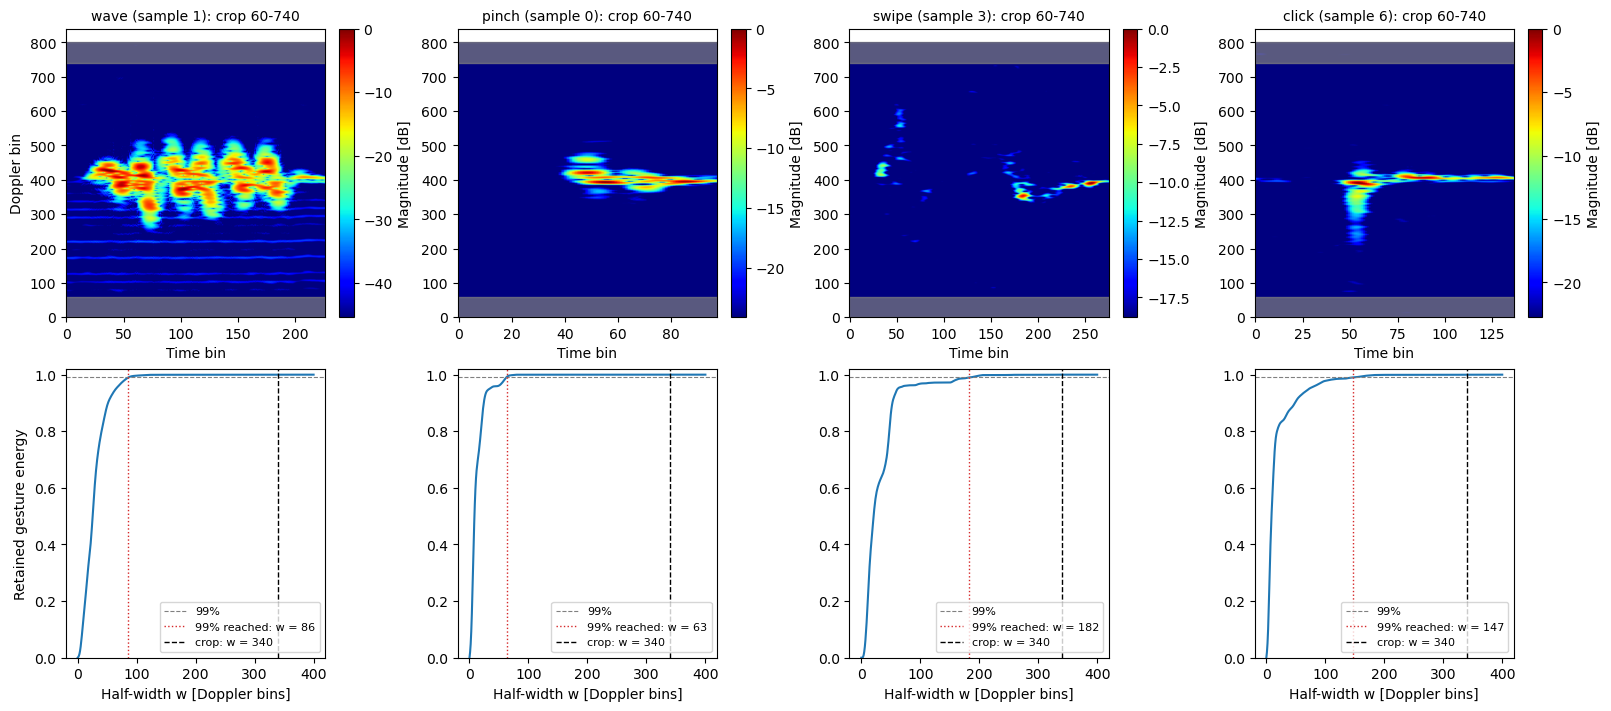

In [12]:
# One training sample per gesture, one column each:
# top: noise-free spectrogram with the bins outside the crop greyed out, bottom: retained share against w
fig, axes = plt.subplots(2, len(GESTURE_EXAMPLES), figsize=(4 * len(GESTURE_EXAMPLES), 7), constrained_layout=True)

for col, i in zip(axes.T, GESTURE_EXAMPLES):
    x_clean = spectrograms_clean[idx_train[i]]
    w = w_kept_train[i]

    # 1. Full noise-free spectrogram (still in dB); grey = Doppler bins outside the crop
    im = col[0].imshow(x_clean, aspect="auto", origin="lower", cmap="jet")
    col[0].axhspan(0, DOPPLER_CROP[0], color="gray", alpha=0.7)
    col[0].axhspan(DOPPLER_CROP[1], x_clean.shape[0], color="gray", alpha=0.7)
    col[0].set_title(f"{GESTURES[labels_train[i]]} (sample {i}): crop {DOPPLER_CROP[0]}-{DOPPLER_CROP[1]}", fontsize=10)
    col[0].set_xlabel("Time bin")
    fig.colorbar(im, ax=col[0], label="Magnitude [dB]")

    # 2. Retained share against w
    col[1].plot(HALF_WIDTHS, retained_train[i])
    col[1].axhline(ENERGY_KEPT, color="gray", linestyle="--", linewidth=0.8, label=f"{ENERGY_KEPT:.0%}")
    col[1].axvline(w, color="C3", linestyle=":", linewidth=1, label=f"{ENERGY_KEPT:.0%} reached: w = {w}")
    col[1].axvline(W_CROP, color="black", linestyle="--", linewidth=1, label=f"crop: w = {W_CROP}")
    col[1].set_ylim(0, 1.02)
    col[1].set_xlabel("Half-width w [Doppler bins]")
    col[1].legend(fontsize=8, loc="lower right")

axes[0, 0].set_ylabel("Doppler bin")
axes[1, 0].set_ylabel("Retained gesture energy")
fig.savefig(FIG_DIR / "prepro_crop.pdf", bbox_inches="tight")
plt.show()

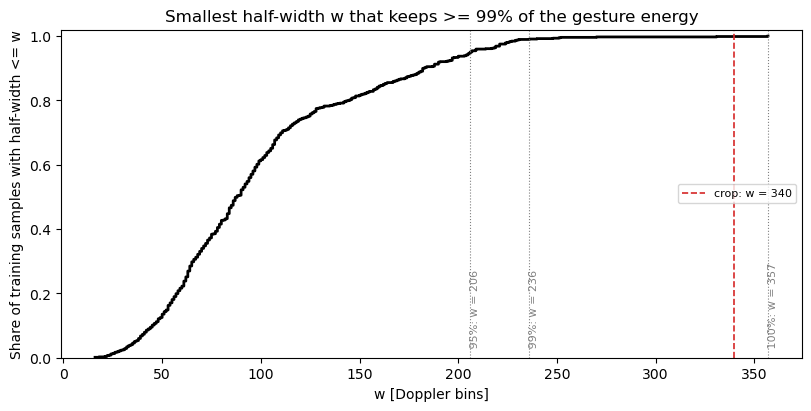

In [13]:
# Cumulative distribution: share of training samples whose w is at most a given value
def ecdf(values):
    v = np.sort(values)
    return v, np.arange(1, len(v) + 1) / len(v)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.step(*ecdf(w_kept_train), where="post", color="black", linewidth=2)

# w needed to cover 95%, 99% and 100% of the training samples
for q in [0.95, 0.99, 1.0]:
    w_q = np.quantile(w_kept_train, q, method="higher")
    ax.axvline(w_q, color="gray", linestyle=":", linewidth=0.8)
    ax.text(w_q, 0.02, f" {q:.0%}: w = {w_q}", rotation=90, va="bottom", fontsize=8, color="gray")
ax.axvline(W_CROP, color="C3", linestyle="--", linewidth=1.2, label=f"crop: w = {W_CROP}")

ax.set_title(f"Smallest half-width w that keeps >= {ENERGY_KEPT:.0%} of the gesture energy")
ax.set_xlabel("w [Doppler bins]")
ax.set_ylabel("Share of training samples with half-width <= w")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, loc="center right")
plt.show()

## Scaling and resize
Every sample gets the **same** Doppler crop, so a Doppler row keeps the same velocity meaning in every sample:
- **Crop:** bins 60–739 (680 bins).
- **Scaling:** $(x - \text{threshold}) / (\max x - \text{threshold})$ on the noise-free spectrogram, so the threshold becomes 0 and the maximum 1.
- **Resize:** linear interpolation to 128 × 128. The Doppler axis is scaled by the same fixed factor (680/128) for every sample; only the time axis is stretched per sample, because the recordings have different lengths.

The cell below runs these steps one by one on a sample and checks that `preprocess_clip` gives the same result.

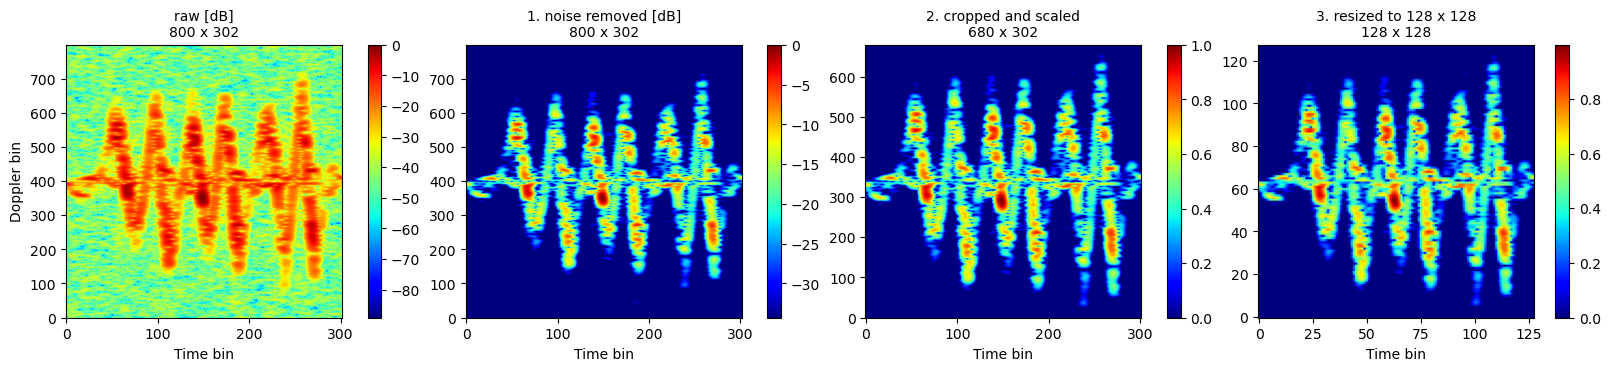

Same as preprocess_clip: True


In [14]:
# The four steps by hand, for one training sample, against preprocess_clip
x = train_specs[2]
x_clean, threshold = remove_noise(x)                          # 1. noise removal
x_crop = x_clean[DOPPLER_CROP[0]:DOPPLER_CROP[1]]             # 2. Doppler crop
x_scaled = (x_crop - threshold) / (x_crop.max() - threshold)  # 3. scaling: threshold -> 0, maximum -> 1
x_img = zoom(x_scaled, (128 / x_scaled.shape[0], 128 / x_scaled.shape[1]), order=1)  # 4. resize

# Crop and scaling are shown together in one panel
steps = {"raw [dB]": x, "1. noise removed [dB]": x_clean,
         "2. cropped and scaled": x_scaled, "3. resized to 128 x 128": x_img}
fig, axes = plt.subplots(1, len(steps), figsize=(16, 3.6), constrained_layout=True)
for ax, (name, img) in zip(axes, steps.items()):
    im = ax.imshow(img, aspect="auto", origin="lower", cmap="jet")
    ax.set_title(f"{name}\n{img.shape[0]} x {img.shape[1]}", fontsize=10)
    ax.set_xlabel("Time bin")
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel("Doppler bin")
fig.savefig(FIG_DIR / "prepro_all_steps.pdf", bbox_inches="tight")
plt.show()

print("Same as preprocess_clip:", np.allclose(np.clip(x_img, 0, 1), preprocess_clip(x)))

In [15]:
# Pre-process every sample (src/preprocessing.py)
X_img = preprocess(spectrograms)
print(f"X_img: {X_img.shape}, values from {X_img.min():.2f} to {X_img.max():.2f}")

X_img: (960, 128, 128), values from 0.00 to 1.00


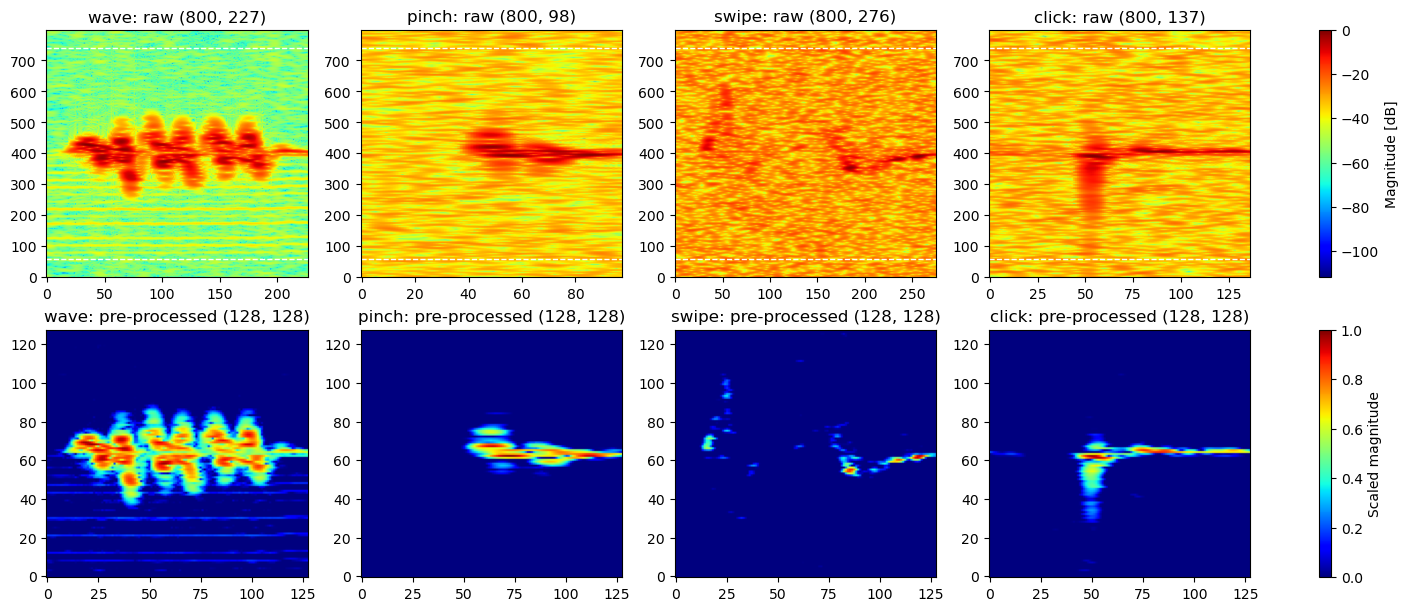

In [16]:
# Before / after pre-processing: one training sample per gesture
raw = [spectrograms[idx_train[i]] for i in GESTURE_EXAMPLES]
vmin, vmax = min(x.min() for x in raw), max(x.max() for x in raw)  # one dB scale for the shared colour bar

fig, axes = plt.subplots(2, len(GESTURE_EXAMPLES), figsize=(14, 6), constrained_layout=True)
for j, (i, x) in enumerate(zip(GESTURE_EXAMPLES, raw)):
    g = GESTURES[labels_train[i]]
    im_raw = axes[0, j].imshow(x, aspect="auto", origin="lower", cmap="jet", vmin=vmin, vmax=vmax)
    for b in DOPPLER_CROP:
        axes[0, j].axhline(b, color="white", linestyle="--", linewidth=1)
    axes[0, j].set_title(f"{g}: raw {x.shape}")
    im_pre = axes[1, j].imshow(X_img[idx_train[i]], aspect="auto", origin="lower", cmap="jet", vmin=0, vmax=1)
    axes[1, j].set_title(f"{g}: pre-processed {X_img[idx_train[i]].shape}")
fig.colorbar(im_raw, ax=axes[0], label="Magnitude [dB]")
fig.colorbar(im_pre, ax=axes[1], label="Scaled magnitude")
fig.savefig(FIG_DIR / "prepro_before_after.pdf", bbox_inches="tight")
plt.show()

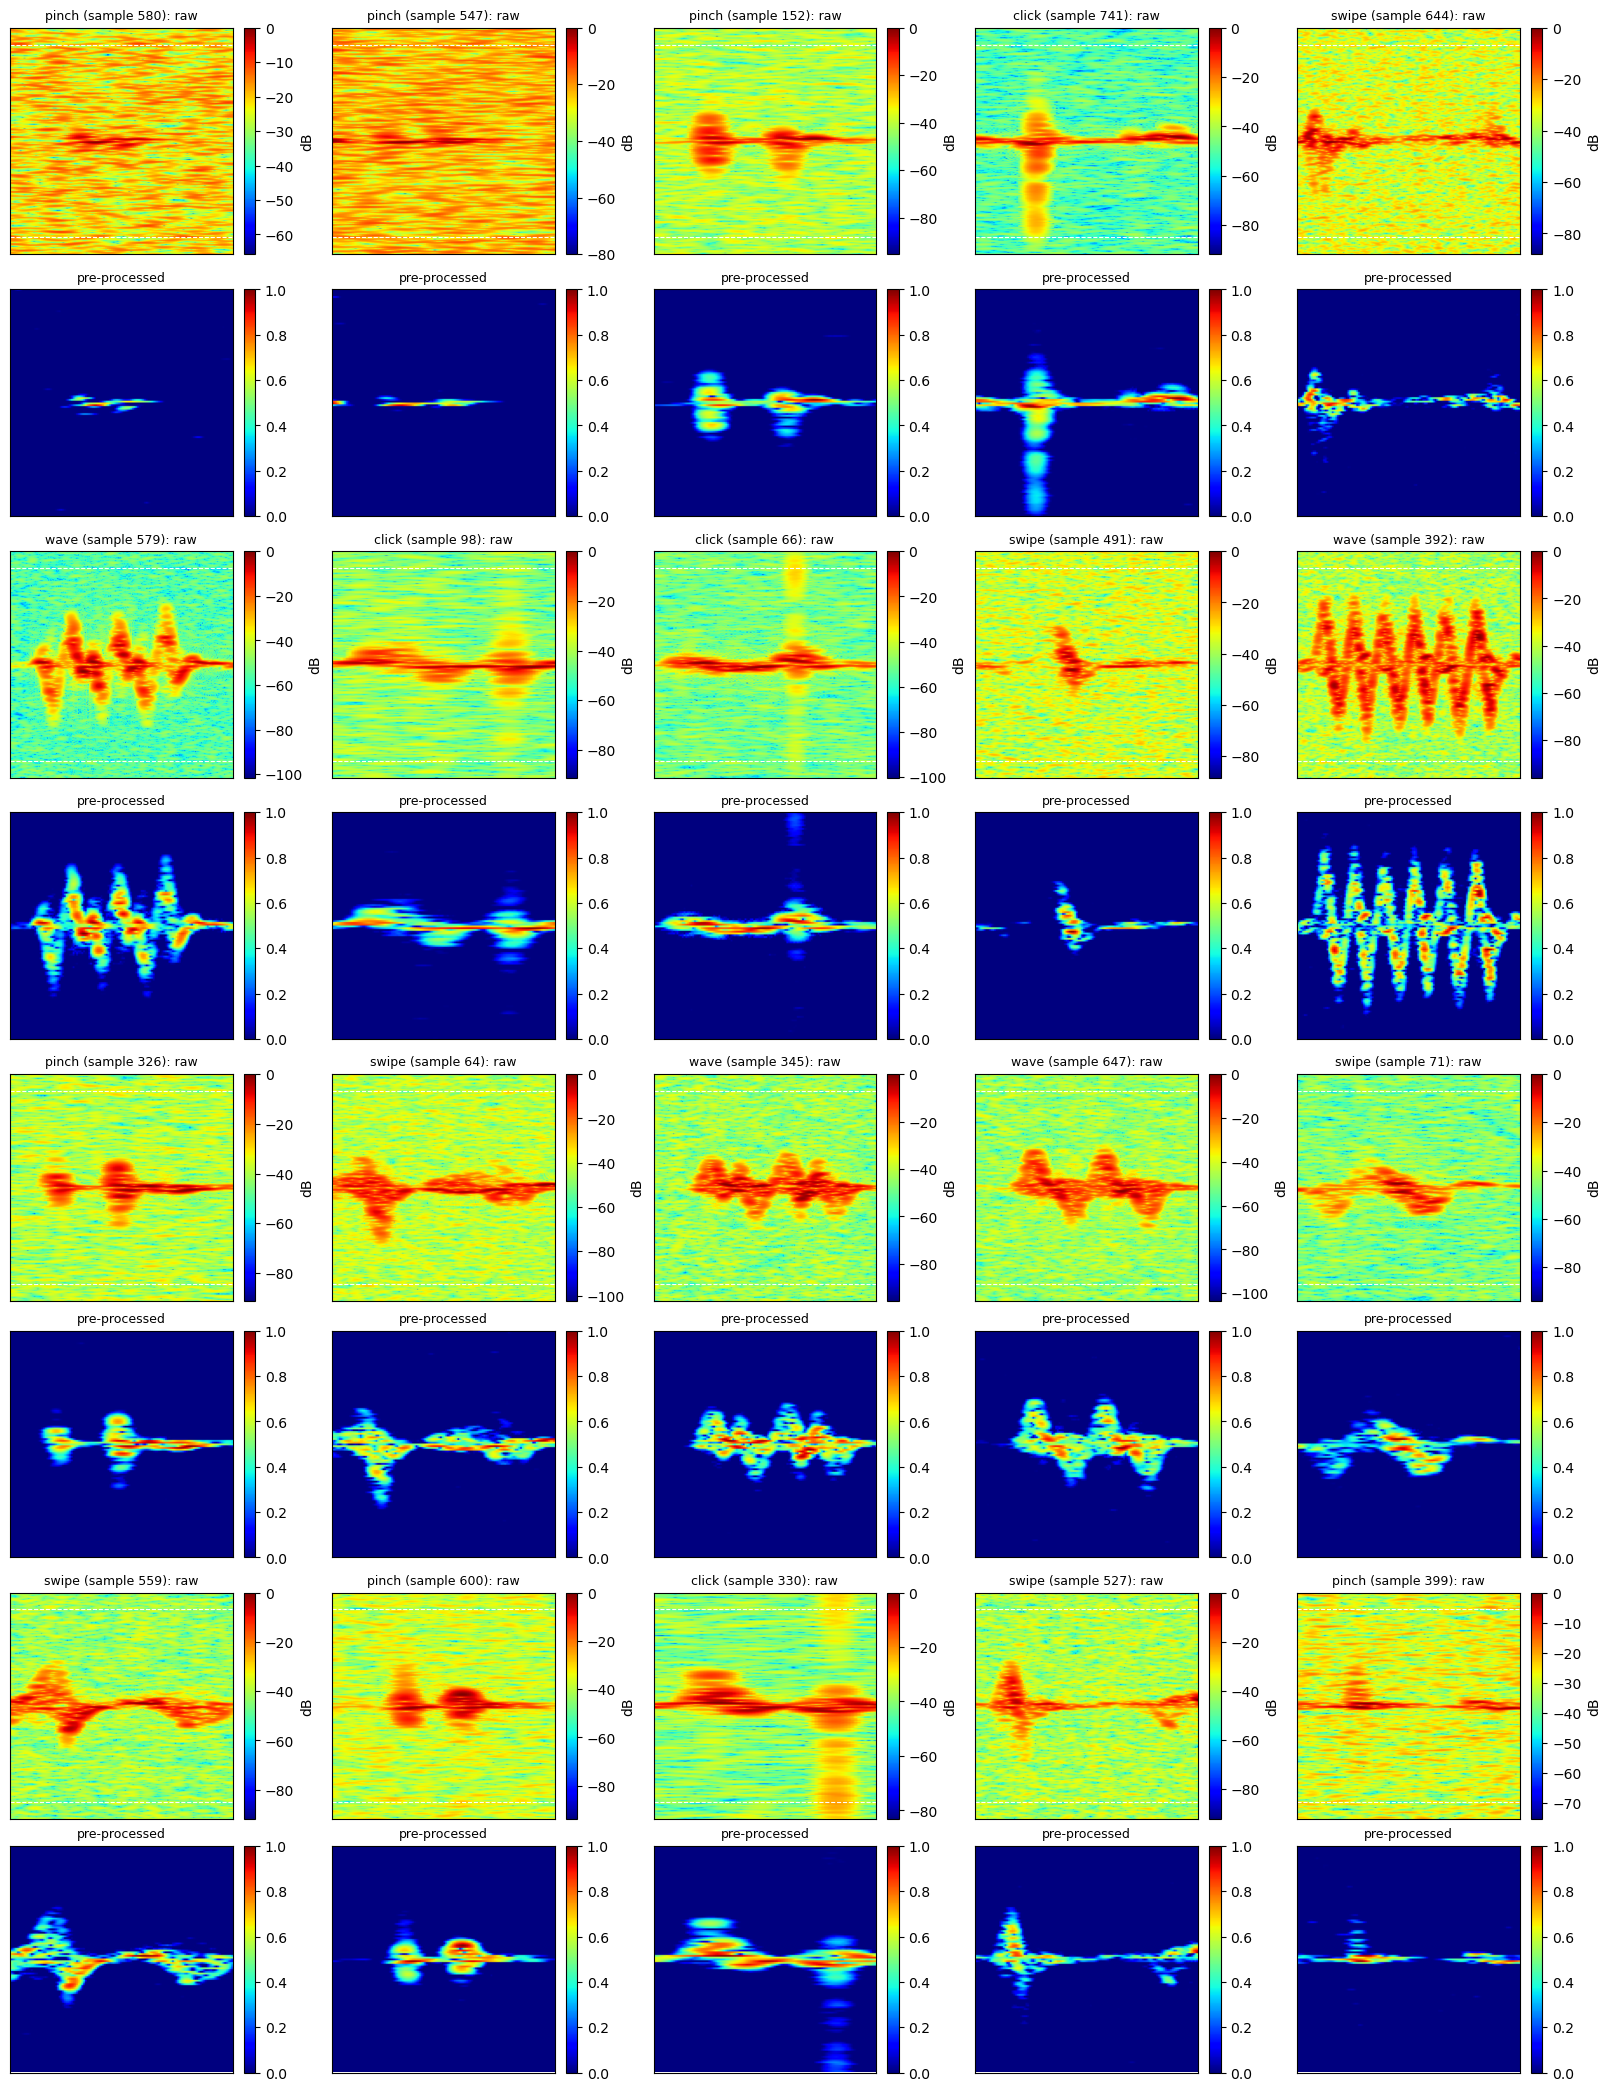

In [17]:
# 20 random training samples: raw spectrogram (crop marked) with its pre-processed image directly below it
N_RANDOM, N_COLS = 20, 5
rng = np.random.default_rng(SEED)
random_examples = rng.choice(len(train_specs), N_RANDOM, replace=False)  # indices into train_specs

n_rows = 2 * int(np.ceil(N_RANDOM / N_COLS))  # a raw row and a pre-processed row per group of N_COLS samples
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.2 * N_COLS, 2.6 * n_rows), constrained_layout=True)

for k, i in enumerate(random_examples):
    ax_raw, ax_pre = axes[2 * (k // N_COLS), k % N_COLS], axes[2 * (k // N_COLS) + 1, k % N_COLS]
    x = train_specs[i]

    im_raw = ax_raw.imshow(x, aspect="auto", origin="lower", cmap="jet")
    for b in DOPPLER_CROP:
        ax_raw.axhline(b, color="white", linestyle="--", linewidth=0.8)
    ax_raw.set_title(f"{GESTURES[labels_train[i]]} (sample {i}): raw", fontsize=9)
    fig.colorbar(im_raw, ax=ax_raw, label="dB")

    im_pre = ax_pre.imshow(preprocess_clip(x), aspect="auto", origin="lower", cmap="jet", vmin=0, vmax=1)
    ax_pre.set_title("pre-processed", fontsize=9)
    fig.colorbar(im_pre, ax=ax_pre)

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()